Use threshold for detect each chili fruit

0: 640x224 15 seeds, 2 placentas, 1 endocarp, 287.8ms
Speed: 2.7ms preprocess, 287.8ms inference, 20.6ms postprocess per image at shape (1, 3, 640, 224)
0 [582, 1293, 208, 857]

0: 640x192 10 seeds, 1 placenta, 1 endocarp, 203.2ms
Speed: 0.9ms preprocess, 203.2ms inference, 8.8ms postprocess per image at shape (1, 3, 640, 192)
1 [1063, 1242, 190, 869]

0: 640x256 8 seeds, 1 placenta, 1 endocarp, 250.0ms
Speed: 1.1ms preprocess, 250.0ms inference, 8.2ms postprocess per image at shape (1, 3, 640, 256)
2 [1607, 1297, 235, 816]

0: 640x224 7 seeds, 1 placenta, 1 endocarp, 255.2ms
Speed: 0.9ms preprocess, 255.2ms inference, 4.9ms postprocess per image at shape (1, 3, 640, 224)
3 [2076, 1322, 206, 799]

0: 640x256 12 seeds, 1 placenta, 1 endocarp, 208.8ms
Speed: 1.0ms preprocess, 208.8ms inference, 9.7ms postprocess per image at shape (1, 3, 640, 256)
4 [2577, 1266, 212, 778]

0: 640x224 3 seeds, 1 placenta, 1 endocarp, 213.4ms
Speed: 1.8ms preproce

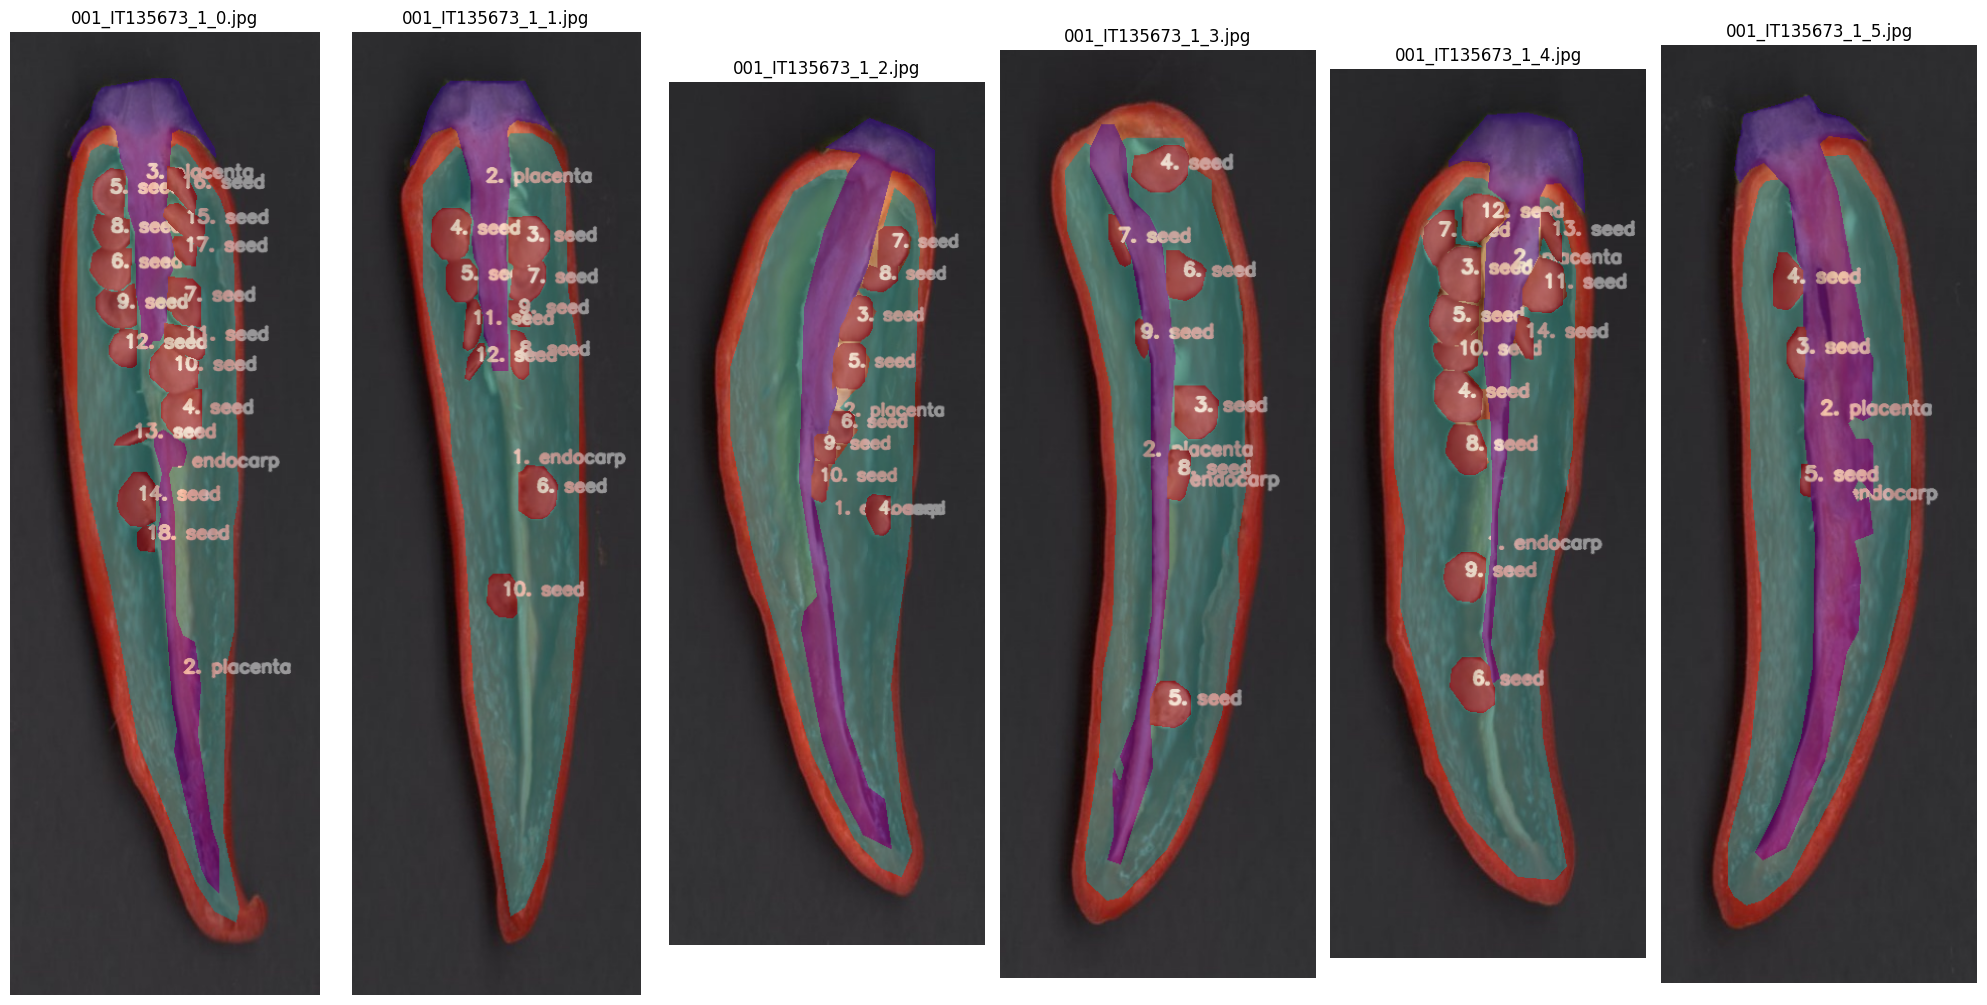

In [2]:
from src.object import Fruits, Chili
from src.detect import DetectModel
from src.segment import SegmentModel

image_path = './data/001_IT135673_1.jpg'

model_detect = DetectModel(model_name='none')
model_seg = SegmentModel(weight_path='./pretrain/yolov8_segment_v1.pt', model_name='yolo', device='cpu')

fruits = Fruits(image_path, model_detect, model_seg)
fruits.show()
# fruits.items[0].rseg

# Tính lại độ đỏ
- loại bỏ các pixel ở vùng màu trắng, hạt ớt cuốn ớt

# Tính lại độ nhăn của trái ớt
- pp cũ tính dựa trên so sánh độ dài contour trước và sau khi xấp xỉ => không chính xác
- định nghĩa lại khái nghiệm độ nhăn
- đề xuất phương pháp tính độ nhăn mới 

# Chiều rộng của trái ớt tính thêm min max
- pp cũ tính trung bình của 10 đường bắt ngang
- có thể tăng lên để chính xác hơn và lấy thêm giá trị min/max thay vì mỗi trung bình
- bỏ phần cuốn và outer

# Tính lại chiều dài thực của trái ớt 
- không tính phần cái cuốn và outer

# Diện tích thành ớt
- cộng trừ các mask để lấy được vùng mask của thành ớt sau đó đếm pixel 
  

# Độ dày thành ớt
- đề xuất phương pháp tính độ dày cho hợp lý (pháp tuyến, lấy diểm gần nhất)

# Tính lại diện tích mặt cắt
- loại bỏ đi phần cuốn ớt (màu xanh, phần bên trong trái vẫn giữ nguyên)
- loại bỏ phần outer bên ngoài

# Tỷ số phần trăm sô pixel màu đỏ trên pixel màu trắng
- có thể đặt ngưỡng để phân biệt màu trắng/đỏ hoặc chia theo class

# Diện tích hạt ớt
- tính cho từng hạt ớt sau đó lấy thông tin sau 
- avg/max/min/sum
- vẽ biểu đồ histogram

# Diện tích phần lõi màu trắng
- class: placenta trừ đi phần cuốn ớt